# Notebook 06 — Embedding-Based Retrieval (Truncated SVD MVP)

**Goal:** build user/item latent embeddings from strictly historical binary interactions, retrieve Top-100 personalized candidates, and evaluate with the **same eligible future positives** as Notebooks 04–05.

**MVP constraints:** 30-day history; max 30 recent distinct items per user (reuse Notebook 05); up to 30,000 most-supported historical items for the SVD training matrix; rank 24; separate model per split cutoff. These limits trade coverage for Windows laptop feasibility. No future interactions or future item properties enter training. This is **not** implicit ALS or production ANN. 

**Install once:** `python -m pip install duckdb pandas numpy scipy scikit-learn pyarrow matplotlib`.

Run with the previous DuckDB connections closed. Set `OPENBLAS_NUM_THREADS=4` in your VS Code/Jupyter environment *before launching the kernel* if BLAS uses too many threads.

## 1. Setup and source validation

In [1]:
from pathlib import Path
import json, time, os
import numpy as np, pandas as pd, duckdb
from scipy import sparse
from sklearn.decomposition import TruncatedSVD
from IPython.display import display

cwd=Path.cwd().resolve()
ROOT=next((p for p in (cwd,*cwd.parents) if (p/'data'/'processed'/'notebook02.duckdb').exists()),None)
if ROOT is None: raise FileNotFoundError('Missing data/processed/notebook02.duckdb. Run Notebooks 02–05 first.')
OUT=ROOT/'data'/'processed'; REPORT=ROOT/'data'/'reports'; REPORT.mkdir(parents=True,exist_ok=True)
con=duckdb.connect(str(OUT/'notebook02.duckdb'))
con.execute("SET memory_limit='4GB'");con.execute('SET threads=4')
q=lambda p:"'"+p.as_posix().replace("'","''")+"'"
splits=('train','validation','test')
existing={x[0] for x in con.execute('SHOW TABLES').fetchall()}
required={f'{s}_{suffix}' for s in splits for suffix in ('cf_user_items','history','positives','pop_scores','enriched_examples')}
assert required.issubset(existing),f'Missing {required-existing}. Run Notebook 05 first.'
print('Root:',ROOT,'DuckDB:',duckdb.__version__)
for s in splits:
    print(s,'cutoff',con.execute(f'SELECT MIN(cutoff_ts),MAX(cutoff_ts) FROM {s}_enriched_examples').fetchone(),
          'history rows',con.execute(f'SELECT COUNT(*) FROM {s}_cf_user_items').fetchone()[0])

Root: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks DuckDB: 1.5.5
train cutoff (1438372073596, 1438372073596) history rows 517283
validation cutoff (1439922087439, 1439922087439) history rows 469133
test cutoff (1441352869447, 1441352869447) history rows 410239


## 2. Config and model definition

For each cutoff, fit SVD on a binary user × item sparse matrix built from Notebook 05's time-safe, capped history. An item's vector is its right singular-vector row scaled by the singular values. For an evaluation user, **fold in** their historical items by a weighted average of the item vectors (a simple, transparent heuristic; not an ALS user-factor estimate). Both user and item vectors are L2-normalized, and ranking uses cosine similarity. Evaluation users with no retained history have zero candidates; no popularity fallback yet.

**Why cap items?** Full-catalog dense retrieval can be expensive; the cap is explicit and measured. The same cap is used independently at each cutoff, selected only from pre-cutoff history.

In [2]:
MAX_ITEMS=30_000      # reduce to 15_000 if memory/runtime is tight
LATENT_DIM=24
TOP_K=100
BATCH_USERS=96
RANDOM_STATE=42
EPS=1e-10
metrics=[]; runs=[]; build_stats=[]

def normalize_rows(a):
    a=np.asarray(a,dtype=np.float32)
    norm=np.linalg.norm(a,axis=1,keepdims=True)
    return np.divide(a,norm,out=np.zeros_like(a),where=norm>EPS)

def evaluate(split,table,ks=(20,50,100)):
    positives,users=con.execute(f'SELECT COUNT(*),COUNT(DISTINCT user_id) FROM {split}_positives').fetchone()
    catalog=con.execute(f'SELECT COUNT(*) FROM {split}_pop_scores').fetchone()[0]
    out=[]
    for k in ks:
        hits,hit_users=con.execute(f"""SELECT COUNT(*),COUNT(DISTINCT c.user_id)
          FROM {table} c JOIN {split}_positives p
          ON c.user_id=p.user_id AND c.item_id=p.item_id
          WHERE c.retrieval_rank<={int(k)}""").fetchone()
        macro=con.execute(f"""WITH pos AS (SELECT user_id,COUNT(*) AS n FROM {split}_positives GROUP BY 1),
        hits AS (SELECT c.user_id,COUNT(*) AS n FROM {table} c
          JOIN {split}_positives p ON c.user_id=p.user_id AND c.item_id=p.item_id
          WHERE c.retrieval_rank<={int(k)} GROUP BY 1)
        SELECT AVG(COALESCE(h.n,0)::DOUBLE/p.n) FROM pos p LEFT JOIN hits h USING(user_id)""").fetchone()[0]
        unique=con.execute(f'SELECT COUNT(DISTINCT item_id) FROM {table} WHERE retrieval_rank<={int(k)}').fetchone()[0]
        out.append(dict(split=split,method='svd',k=int(k),eligible_positive_pairs=int(positives),
          users=int(users),hits=int(hits),recall_micro=hits/positives if positives else None,
          recall_macro_user=float(macro) if macro is not None else None,
          hit_rate=hit_users/users if users else None,unique_recommended_items=int(unique),
          catalog_coverage=unique/catalog if catalog else None))
    return out

## 3. Train split-specific SVD and export item/user embeddings

In [3]:
def train_embeddings(split):
    start=time.perf_counter()
    cutoff=int(con.execute(f'SELECT MIN(cutoff_ts) FROM {split}_enriched_examples').fetchone()[0])
    assert con.execute(f'SELECT COUNT(DISTINCT cutoff_ts) FROM {split}_enriched_examples').fetchone()[0]==1
    # Trainable item universe: top supported items from pre-cutoff capped history only.
    item_df=con.execute(f"""SELECT h.item_id,COUNT(*) AS support
       FROM {split}_cf_user_items h JOIN {split}_pop_scores p USING(item_id)
       GROUP BY 1 ORDER BY support DESC,h.item_id ASC LIMIT {MAX_ITEMS}""").df()
    item_ids=item_df.item_id.to_numpy(dtype=np.int64)
    assert len(item_ids)>LATENT_DIM+2
    con.register('svd_allowed_items',item_df[['item_id']])
    hist=con.execute(f"""SELECT h.user_id,h.item_id
       FROM {split}_cf_user_items h JOIN svd_allowed_items a USING(item_id)
       ORDER BY h.user_id,h.item_id""").df()
    con.unregister('svd_allowed_items')
    user_ids=np.sort(hist.user_id.unique().astype(np.int64))
    user_index=pd.Index(user_ids); item_index=pd.Index(item_ids)
    row=user_index.get_indexer(hist.user_id.to_numpy())
    col=item_index.get_indexer(hist.item_id.to_numpy())
    assert (row>=0).all() and (col>=0).all()
    X=sparse.coo_matrix((np.ones(len(row),dtype=np.float32),(row,col)),
                        shape=(len(user_ids),len(item_ids)),dtype=np.float32).tocsr()
    X.sum_duplicates(); X.data[:]=1.0
    print(split,'matrix',X.shape,'nnz',X.nnz,'density',round(X.nnz/(X.shape[0]*X.shape[1]),7))
    model=TruncatedSVD(n_components=LATENT_DIM,n_iter=5,random_state=RANDOM_STATE)
    model.fit(X)
    # V * Sigma; user vector = normalized weighted average of interacted item vectors.
    item_emb=normalize_rows((model.components_.T * model.singular_values_).astype(np.float32))
    user_sum=X @ item_emb
    user_emb=normalize_rows(user_sum)
    # Export compact, reproducible embeddings; IDs never inferred from array positions alone.
    columns=[f'dim_{i:02d}' for i in range(LATENT_DIM)]
    item_out=pd.DataFrame(item_emb,columns=columns);item_out.insert(0,'item_id',item_ids)
    user_out=pd.DataFrame(user_emb,columns=columns);user_out.insert(0,'user_id',user_ids)
    item_path=OUT/f'{split}_svd_item_embeddings.parquet'
    user_path=OUT/f'{split}_svd_user_embeddings.parquet'
    item_out.to_parquet(item_path,index=False);user_out.to_parquet(user_path,index=False)
    seconds=time.perf_counter()-start
    stats=dict(split=split,cutoff_ts=cutoff,training_users=len(user_ids),training_items=len(item_ids),
      training_nonzeros=int(X.nnz),latent_dim=LATENT_DIM,explained_variance_ratio_sum=float(model.explained_variance_ratio_.sum()),
      fit_and_export_seconds=seconds,item_embedding_path=item_path.name,user_embedding_path=user_path.name)
    print('Trained:',stats)
    return item_ids,item_emb,user_ids,user_emb,stats


## 4. Batched exact cosine retrieval

Rank up to 30,000 candidate items per evaluation user in bounded batches. The score matrix is `batch_users × trainable_items`, not `all_users × all_items`. Remove the user's **full 30-day history**, including items outside the 30-item SVD seed cap. This is an exact dense-vector scan over the capped item universe, **not FAISS/ANN**. Users with no nonzero embedding are left uncovered.

Time includes embedding lookup, score computation, history masking and top-K selection. It excludes SVD training and parquet serialization.

In [4]:
def retrieve(split,item_ids,item_emb,user_ids,user_emb):
    t0=time.perf_counter()
    eval_users=con.execute(f'SELECT DISTINCT user_id FROM {split}_positives ORDER BY user_id').df().user_id.to_numpy(dtype=np.int64)
    # Historical exclusions for these evaluation users, from the full 30-day history.
    seen_df=con.execute(f"""SELECT h.user_id,h.item_id FROM {split}_history h
      JOIN (SELECT DISTINCT user_id FROM {split}_positives) p USING(user_id)""").df()
    seen_map={int(u):set(g.item_id.to_numpy(dtype=np.int64).tolist()) for u,g in seen_df.groupby('user_id',sort=False)}
    idx=pd.Index(user_ids).get_indexer(eval_users)
    item_idx=pd.Index(item_ids)
    result=[]; nonzero_users=0
    for start in range(0,len(eval_users),BATCH_USERS):
        uu=eval_users[start:start+BATCH_USERS]
        ix=idx[start:start+BATCH_USERS]
        valid=ix>=0
        if not valid.any(): continue
        u=uu[valid]; v=user_emb[ix[valid]]
        active=np.linalg.norm(v,axis=1)>EPS
        if not active.any(): continue
        u=u[active];v=v[active]
        nonzero_users+=len(u)
        scores=np.asarray(v @ item_emb.T,dtype=np.float32)
        for j,user in enumerate(u):
            seen=seen_map.get(int(user),())
            if seen:
                blocked=item_idx.get_indexer(np.fromiter(seen,dtype=np.int64))
                blocked=blocked[blocked>=0]
                scores[j,blocked]=-np.inf
        for j,user in enumerate(u):
            s=scores[j]
            finite=int(np.isfinite(s).sum())
            if finite==0:continue
            k=min(TOP_K,finite)
            # argpartition is fast; final order deterministic on score ties by item_id.
            ix_top=np.argpartition(-s,k-1)[:k]
            ix_top=ix_top[np.lexsort((item_ids[ix_top],-s[ix_top]))]
            for rank,ii in enumerate(ix_top,1):
                result.append((int(user),int(item_ids[ii]),float(s[ii]),int(rank),'svd'))
    seconds=time.perf_counter()-t0
    frame=pd.DataFrame(result,columns=['user_id','item_id','retrieval_score','retrieval_rank','retrieval_source'])
    table=f'{split}_svd_candidates'
    con.register('svd_candidates_frame',frame)
    con.execute(f'CREATE OR REPLACE TABLE {table} AS SELECT * FROM svd_candidates_frame')
    con.unregister('svd_candidates_frame')
    total,covered=con.execute(f'SELECT COUNT(*),COUNT(DISTINCT user_id) FROM {table}').fetchone()
    n_eval=len(eval_users)
    assert total==len(frame)
    assert con.execute(f'SELECT COUNT(*)-COUNT(DISTINCT (user_id,item_id)) FROM {table}').fetchone()[0]==0
    assert con.execute(f"""SELECT COUNT(*) FROM {table} c JOIN {split}_history h
      ON c.user_id=h.user_id AND c.item_id=h.item_id""").fetchone()[0]==0
    assert con.execute(f"""SELECT COUNT(*) FROM
      (SELECT user_id,MIN(retrieval_rank) lo,MAX(retrieval_rank) hi,COUNT(*) n
       FROM {table} GROUP BY user_id) WHERE lo<>1 OR hi<>n OR n>{TOP_K}""").fetchone()[0]==0
    path=OUT/f'{split}_svd_top100.parquet'
    con.execute(f'COPY {table} TO {q(path)} (FORMAT PARQUET)')
    info=dict(split=split,method='svd',table=table,evaluation_users=n_eval,
      covered_users=int(covered),user_coverage=covered/n_eval if n_eval else None,
      nonzero_embedding_users=int(nonzero_users),candidate_rows=int(total),
      build_seconds=seconds,build_ms_per_user_amortized=1000*seconds/n_eval if n_eval else None,
      candidates_path=path.name)
    print('Retrieval:',info)
    return info


## 5. Execute all chronological splits

In [6]:
for split in splits:
    item_ids,item_emb,user_ids,user_emb,stats=train_embeddings(split)
    build_stats.append(stats)
    runs.append(retrieve(split,item_ids,item_emb,user_ids,user_emb))
    metrics.extend(evaluate(split,f'{split}_svd_candidates'))
    del item_ids,item_emb,user_ids,user_emb
metrics_df=pd.DataFrame(metrics)
display(metrics_df[metrics_df.split=='validation'].round(5))


train matrix (266054, 30000) nnz 369036 density 4.62e-05
Trained: {'split': 'train', 'cutoff_ts': 1438372073596, 'training_users': 266054, 'training_items': 30000, 'training_nonzeros': 369036, 'latent_dim': 24, 'explained_variance_ratio_sum': 0.02163117006421089, 'fit_and_export_seconds': 3.837498699999742, 'item_embedding_path': 'train_svd_item_embeddings.parquet', 'user_embedding_path': 'train_svd_user_embeddings.parquet'}
Retrieval: {'split': 'train', 'method': 'svd', 'table': 'train_svd_candidates', 'evaluation_users': 4110, 'covered_users': 3285, 'user_coverage': 0.7992700729927007, 'nonzero_embedding_users': 3285, 'candidate_rows': 328500, 'build_seconds': 1.0659593000000314, 'build_ms_per_user_amortized': 0.2593574939172826, 'candidates_path': 'train_svd_top100.parquet'}
validation matrix (245869, 30000) nnz 338991 density 4.6e-05
Trained: {'split': 'validation', 'cutoff_ts': 1439922087439, 'training_users': 245869, 'training_items': 30000, 'training_nonzeros': 338991, 'latent_d

,split,method,k,eligible_positive_pairs,users,hits,recall_micro,recall_macro_user,hit_rate,unique_recommended_items,catalog_coverage
3,validation,svd,20,9020,3657,141,0.01563,0.02050,0.03309,21663,0.18407
4,validation,svd,50,9020,3657,230,0.02550,0.03232,0.05223,27246,0.23151
5,validation,svd,100,9020,3657,355,0.03936,0.04618,0.07274,29162,0.24779


## 6. Compare to previous baselines (same positive cohort)

,method,recall_micro,hit_rate,catalog_coverage
38,cooccurrence,0.08736,0.13946,0.22630
44,jaccard,0.08237,0.13344,0.25852
41,cosine,0.07672,0.12606,0.26158
5,svd,0.03936,0.07274,0.24779
20,decayed,0.03670,0.06262,0.00140
17,global,0.03415,0.05934,0.00146


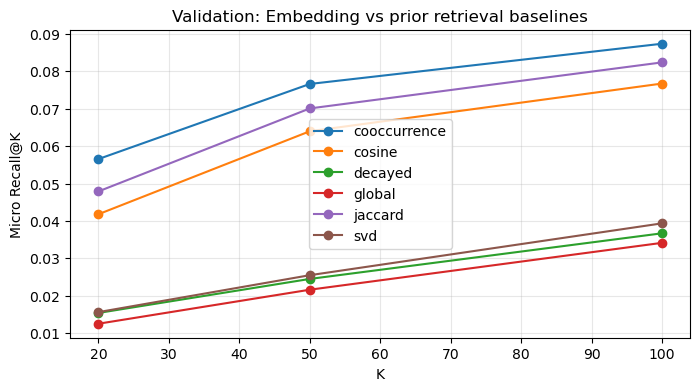

In [7]:
frames=[metrics_df]
for filename in ('notebook04_popularity_report.json','notebook05_item_cf_report.json'):
    path=REPORT/filename
    if path.exists():
        old=json.loads(path.read_text(encoding='utf-8'))
        frames.append(pd.DataFrame(old['metrics']))
    else:print('Optional baseline report not found:',path)
comparison=pd.concat(frames,ignore_index=True)
show=comparison[(comparison.split=='validation')&(comparison.k==100)][
    ['method','recall_micro','hit_rate','catalog_coverage']].sort_values('recall_micro',ascending=False)
display(show.round(5))
import matplotlib.pyplot as plt
fig,ax=plt.subplots(figsize=(8,4))
for method,g in comparison[comparison.split=='validation'].groupby('method'):
    ax.plot(g.k,g.recall_micro,marker='o',label=method)
ax.set(xlabel='K',ylabel='Micro Recall@K',title='Validation: Embedding vs prior retrieval baselines')
ax.grid(alpha=.3);ax.legend();plt.show()

## 7. Save metrics and reproducibility report

In [8]:
metrics_df.to_csv(REPORT/'notebook06_retrieval_metrics.csv',index=False)
def safe(x):
    if isinstance(x,dict):return {str(k):safe(v) for k,v in x.items()}
    if isinstance(x,(list,tuple)):return [safe(v) for v in x]
    if isinstance(x,np.integer):return int(x)
    if isinstance(x,np.floating):return float(x) if np.isfinite(x) else None
    if isinstance(x,np.bool_):return bool(x)
    return x
report={'notebook':'06_embedding_svd_retrieval','algorithm':'TruncatedSVD + normalized history-mean fold-in + exact capped dense scan',
 'history_window_days':30,'max_history_items_per_user':30,'max_training_items':MAX_ITEMS,
 'latent_dim':LATENT_DIM,'max_k':TOP_K,'batch_users':BATCH_USERS,'random_state':RANDOM_STATE,
 'evaluation':'Same capped eligible future positives and 30-day seen filtering as Notebooks 04–05',
 'build_stats':build_stats,'runs':runs,'metrics':metrics,
 'limitations':['SVD is not ALS, neural embedding, or FAISS ANN',
 'Only the top-supported historical items are embedded; missing/cold items cannot be retrieved',
 'User embeddings are history-mean item vectors, not fitted latent user factors',
 'SVD uses capped 30-item/user binary histories, not complete interaction frequency',
 'Capped eligible positives are not an unbiased full-future ground truth',
 'No impressions: metrics are not real CTR/CVR or causal business impact',
 'Batch retrieval time excludes model fit and file writes and is not production request p95']}
path=REPORT/'notebook06_svd_report.json'
path.write_text(json.dumps(safe(report),indent=2,allow_nan=False),encoding='utf-8')
print('Saved report:',path)
print('Saved metrics:',REPORT/'notebook06_retrieval_metrics.csv')
print('Saved candidate and embedding Parquet files to:',OUT)
con.close()

Saved report: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook06_svd_report.json
Saved metrics: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\reports\notebook06_retrieval_metrics.csv
Saved candidate and embedding Parquet files to: C:\YR_Python_Code\multi-stage-ads-recommendation\notebooks\data\processed


## 8. Handoff to Notebook 07

Upload `data/reports/notebook06_svd_report.json` for review. Notebook 07 will add **FAISS ANN** and compare exact vs approximate search latency and recall, using the embeddings generated here. Keep validation for model selection; test is for confirmation only.